# 02b Overcount check: spectral heart rate and a second detector

People: S010 (possible double counting), S097 and S030 (no device beats), S042 (has ECG, checks the spectral method), S045 (clean, 99% device match).

1. **Spectral rate** per 30 s scored epoch: strongest peak of the filtered BVP spectrum in 0.5 to 3.3 Hz. Ratio = our count rate / spectral rate. Near 1 is fine, near 2 means double counting, near 0.5 means the spectrum took the second harmonic.
2. **Second detector**: Elgendi 2013 (neurokit2), a different method from MSPTD, same filtered signal, same chunking and start. Peaks paired with ours within 50 ms.

In [1]:
import os
%load_ext autoreload
%autoreload 2
import sys, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from config import Config
from recording import Recording
from beats import detect_beats_chunked, match_beats
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
FIG_DIR = PROJECT / "notebooks" / "figs"
plt.rcParams.update({"font.size": 8})
CFG = Config()
PEOPLE = ["S010", "S097", "S030", "S042", "S045"]

In [2]:
# LOGIC: heart rate from the spectrum of one stretch of filtered BVP: subtract the
#   mean, Hann window, zero-pad to a 0.01 Hz grid, take the frequency of the largest
#   power between f_lo and f_hi, times 60.
# EDGE CASES: a flat stretch (all zeros) returns NaN.
# NOT HANDLED: harmonic ambiguity: if the second harmonic is stronger than the
#   fundamental, the result is twice the true rate (seen as a ratio near 0.5).
# CHECKED BY: cell below, on a synthetic 1.2 Hz pulse train (must give 72 bpm).
def spectral_rate(x, fs=64, f_lo=0.5, f_hi=3.3, df=0.01):
    x = np.asarray(x, "float64") - np.mean(x)
    if not np.any(x):
        return float("nan")
    n = max(x.size, int(round(fs / df)))
    p = np.abs(np.fft.rfft(x * np.hanning(x.size), n)) ** 2
    f = np.fft.rfftfreq(n, 1 / fs)
    m = (f >= f_lo) & (f <= f_hi)
    return float(60 * f[m][np.argmax(p[m])])

t = np.arange(30 * 64) / 64
pulse = np.exp(-((t % (1 / 1.2)) - 0.15) ** 2 / 0.003)  # narrow pulse with harmonics
print("synthetic 72 bpm ->", spectral_rate(pulse), "bpm")
assert abs(spectral_rate(pulse) - 72) < 1

synthetic 72 bpm -> 72.0 bpm


In [3]:
# LOGIC: for each person, per kept epoch (wrist window): our count rate, Elgendi
#   count rate, spectral rate, and for S042 the ECG rate (R-peaks moved onto the
#   wrist clock with its own clock model). Elgendi runs on the same filtered BVP,
#   chunked, from the same start as ours. Over all scored sleep: pair the two
#   detectors' beats within 50 ms.
# EDGE CASES: an Elgendi chunk that fails is reported, not filled.
# NOT HANDLED: none.
# CHECKED BY: our per-person beat count must equal notebook 02 (out_beats_all35.csv).
B02 = pd.read_csv(PROJECT / "notebooks" / "out_beats_all35.csv", index_col=0)
EP, rows = {}, []
for s in PEOPLE:
    rec = Recording.load(s, DATA_ROOT, CFG)
    fs, n = CFG.fs, CFG.fs * CFG.epoch_s
    x, t0 = rec.bvp_filt, rec.t64[0]
    start = max(0, rec.scoring["anchor"] - CFG.detect_pre_anchor_s * fs)
    e_idx, e_t, e_fail = detect_beats_chunked(x, fs, "elgendi", start, CFG.detect_chunk_s, CFG.detect_overlap_s)
    e_t = e_t + t0
    ours = rec.beat_times[rec.in_scored(rec.beat_times)]
    elg = e_t[rec.in_scored(e_t)]
    assert len(ours) == B02.loc[s, "ppg_beats"]
    ia, ib = match_beats(ours, elg, CFG.match_tol)
    ecg = rec.ecg_beats if rec.has_ecg else None
    ss = rec.epochs[rec.epochs.keep]["start_sample_wrist"].to_numpy()
    r = []
    for a in ss:
        ta = t0 + a / fs
        r.append({"t": ta,
                  "ours_bpm": 2 * np.sum((rec.beat_idx >= a) & (rec.beat_idx < a + n)),
                  "elg_bpm": 2 * np.sum((e_idx >= a) & (e_idx < a + n)),
                  "spec_bpm": spectral_rate(x[a:a + n], fs),
                  "ecg_bpm": 2 * np.sum((ecg >= ta) & (ecg < ta + CFG.epoch_s)) if ecg is not None else np.nan})
    ep = pd.DataFrame(r); ep["ratio"] = ep.ours_bpm / ep.spec_bpm
    EP[s] = ep
    rows.append({"subject": s, "epochs": len(ep), "ours_beats": len(ours), "elg_beats": len(elg),
                 "elg_failed_min": sum(b - a for a, b in e_fail) / 60,
                 "pct_ours_with_elg": 100 * len(ia) / len(ours), "pct_elg_with_ours": 100 * len(ib) / max(len(elg), 1),
                 "elg_over_ours": len(elg) / len(ours),
                 "median_ratio": ep.ratio.median(), "pct_ratio_over_1.5": 100 * (ep.ratio > 1.5).mean(),
                 "pct_ratio_under_0.67": 100 * (ep.ratio < 0.67).mean(),
                 "median_ours_bpm": ep.ours_bpm.median(), "median_spec_bpm": ep.spec_bpm.median(),
                 "median_ecg_bpm": ep.ecg_bpm.median()})
    del rec; gc.collect()
    print(s, end=" ", flush=True)
R = pd.DataFrame(rows).set_index("subject")
print(); print(R.round(2).T.to_string())

S010 

./.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


S097 

./.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


S030 

./.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


S042 

S045 


subject                   S010      S097      S030      S042      S045
epochs                  824.00    784.00    843.00    773.00    821.00
ours_beats            39517.00  23998.00  31204.00  31776.00  28924.00
elg_beats             38586.00  21892.00  29926.00  31812.00  29033.00
elg_failed_min            0.00      0.00      0.00      0.00      0.00
pct_ours_with_elg        96.80     82.05     90.78     99.92     99.84
pct_elg_with_ours        99.14     89.94     94.66     99.81     99.47
elg_over_ours             0.98      0.91      0.96      1.00      1.00
median_ratio              1.00      1.01      1.00      1.00      1.00
pct_ratio_over_1.5        2.43      4.08      7.24      0.26      0.12
pct_ratio_under_0.67      0.00      2.42      0.00      0.00      0.00
median_ours_bpm          96.00     60.00     72.00     82.00     70.00
median_spec_bpm          97.20     56.40     71.40     81.60     69.00
median_ecg_bpm             NaN       NaN       NaN     82.00       NaN


./.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


In [4]:
# S042 only: is the spectral rate itself right? Compare both to ECG per epoch.
e = EP["S042"]
for col in ["spec_bpm", "ours_bpm", "elg_bpm"]:
    d = e[col] - e.ecg_bpm
    print(f"S042 {col} minus ECG: median {d.median():+.1f} bpm, within 6 bpm in {100 * (d.abs() <= 6).mean():.0f}% of epochs")

S042 spec_bpm minus ECG: median +0.0 bpm, within 6 bpm in 96% of epochs
S042 ours_bpm minus ECG: median +0.0 bpm, within 6 bpm in 98% of epochs
S042 elg_bpm minus ECG: median +0.0 bpm, within 6 bpm in 99% of epochs


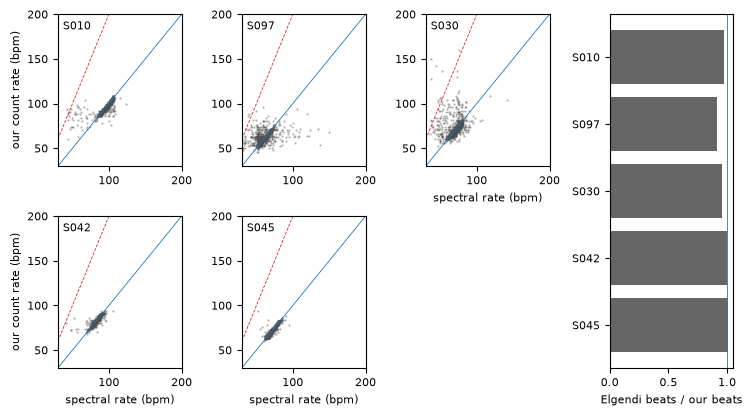

In [5]:
fig = plt.figure(figsize=(7.5, 4.2))
gs = fig.add_gridspec(2, 4)
lim = (30, 200)
for k, s in enumerate(PEOPLE):
    ax = fig.add_subplot(gs[k // 3, k % 3])
    e = EP[s]
    ax.plot(e.spec_bpm, e.ours_bpm, ".", ms=1.5, alpha=0.3, color="0.3", rasterized=True)
    ax.plot(lim, lim, color="tab:blue", lw=0.6); ax.plot(lim, [2 * v for v in lim], color="tab:red", lw=0.6, ls="--")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.text(0.04, 0.9, s, transform=ax.transAxes)
    if k % 3 == 0: ax.set_ylabel("our count rate (bpm)")
    if k // 3 == 1 or k == 2: ax.set_xlabel("spectral rate (bpm)")
ax = fig.add_subplot(gs[:, 3])
ax.barh(R.index, R.elg_over_ours, color="0.4"); ax.axvline(1, color="tab:blue", lw=0.6)
ax.invert_yaxis(); ax.set_xlabel("Elgendi beats / our beats")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_overcount_check.png", dpi=150); plt.show()
R.to_csv(PROJECT / "notebooks" / "out_overcount_check.csv")